# Credit Risk Analysis – Home Credit Default Risk

**Author:** Bui Anh Kiet
**Tools:** Python (pandas, NumPy, Matplotlib, Seaborn, scikit-learn)
**Data:** [Home Credit Default Risk – Kaggle](https://www.kaggle.com/competitions/home-credit-default-risk)

---

## 1. Business Context

Home Credit provides consumer loans to people with little or no credit history. Every loan that is not repaid (*default*) is a direct loss for the lender, while every good applicant who is rejected is lost revenue.

In this analysis I act as a **Data Analyst in the Credit Risk team**. The audience is the **Credit Risk Manager**, who wants to know:

1. **What does the loan portfolio look like** – who are the clients and what is the overall level of risk?
2. **Which client characteristics are most strongly linked to default?**
3. **Does credit history from other institutions (Credit Bureau) help predict risk?**
4. **How can clients be grouped into risk segments** (low / medium / high) to support lending decisions?

## Table of Contents
1. Business Context
2. Data Loading & First Look
3. Data Cleaning & Feature Engineering
4. Portfolio Overview
5. Risk Drivers – What Drives Default?
6. Credit Bureau History
7. Risk Segmentation – Scoring Model
8. Conclusions & Recommendations

## 2. Data Loading & First Look

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.3f}".format)

# --- One consistent style for all charts ---
BASE = "#4C6A92"      # main colour (risk below average)
RISK = "#C8553D"      # accent colour (risk above average)
GREY = "#9AA3AF"
DARK = "#2F3640"

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.edgecolor": GREY,
})

os.makedirs("images", exist_ok=True)

In [2]:
app = pd.read_csv("application_train_.csv")
bureau = pd.read_csv("bureau.csv")
col_desc = pd.read_csv("HomeCredit_columns_description.csv", encoding="latin-1")

print(f"application_train: {app.shape[0]:,} rows × {app.shape[1]} columns")
print(f"bureau:            {bureau.shape[0]:,} rows × {bureau.shape[1]} columns")
app.head()

application_train: 307,511 rows × 122 columns
bureau:            1,716,428 rows × 17 columns


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,...,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,"202,500.000","406,597.500","24,700.500","351,000.000",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.019,-9461,-637,"-3,648.000",-2120,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.000,0.000,0.000,0.000,0.000,1.000
1,100003,0,Cash loans,F,N,N,0,"270,000.000","1,293,502.500","35,698.500","1,129,500.000",Family,State servant,Higher education,Married,House / apartment,0.004,-16765,-1188,"-1,186.000",-291,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.000,0.000,0.000,0.000,0.000,0.000
2,100004,0,Revolving loans,M,Y,Y,0,"67,500.000","135,000.000","6,750.000","135,000.000",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010,-19046,-225,"-4,260.000",-2531,26.000,1,1,1,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.000,0.000,0.000,0.000,0.000,0.000
3,100006,0,Cash loans,F,N,Y,0,"135,000.000","312,682.500","29,686.500","297,000.000",Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.008,-19005,-3039,"-9,833.000",-2437,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,"121,500.000","513,000.000","21,865.500","513,000.000",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.029,-19932,-3038,"-4,311.000",-3458,NaN,1,1,0,...,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0.000,0.000,0.000,0.000,0.000,0.000


Each row in `application_train` is **one loan application** (`SK_ID_CURR`).
Target variable `TARGET`: **1** = the client had payment difficulties (default), **0** = the client repaid on time.

In [3]:
default_rate = app["TARGET"].mean()
print(f"Applications:           {len(app):,}")
print(f"Defaults:               {app['TARGET'].sum():,}")
print(f"Default rate (avg):     {default_rate:.2%}")
print(f"Duplicate SK_ID_CURR:   {app['SK_ID_CURR'].duplicated().sum()}")

app.dtypes.value_counts()

Applications:           307,511
Defaults:               24,825
Default rate (avg):     8.07%
Duplicate SK_ID_CURR:   0


float64    65
int64      41
str        16
Name: count, dtype: int64

**Observation:** about **8.1%** of clients default – the data is **imbalanced** (92% / 8%).
That is why throughout the analysis I compare the *default rate within each group* with the portfolio average (8.1%), rather than looking at raw counts.

## 3. Data Cleaning & Feature Engineering

### 3.1 Missing values

In [4]:
missing = (app.isna().mean()
              .sort_values(ascending=False)
              .rename("pct_missing")
              .to_frame())
print(f"Columns with missing values:   {(missing.pct_missing > 0).sum()} / {app.shape[1]}")
print(f"Columns with > 40% missing:    {(missing.pct_missing > 0.40).sum()}")
missing.head(10)

Columns with missing values:   67 / 122
Columns with > 40% missing:    49


,pct_missing
COMMONAREA_AVG,0.699
COMMONAREA_MODE,0.699
COMMONAREA_MEDI,0.699
NONLIVINGAPARTMENTS_MEDI,0.694
NONLIVINGAPARTMENTS_MODE,0.694
NONLIVINGAPARTMENTS_AVG,0.694
FONDKAPREMONT_MODE,0.684
LIVINGAPARTMENTS_AVG,0.684
LIVINGAPARTMENTS_MEDI,0.684
LIVINGAPARTMENTS_MODE,0.684


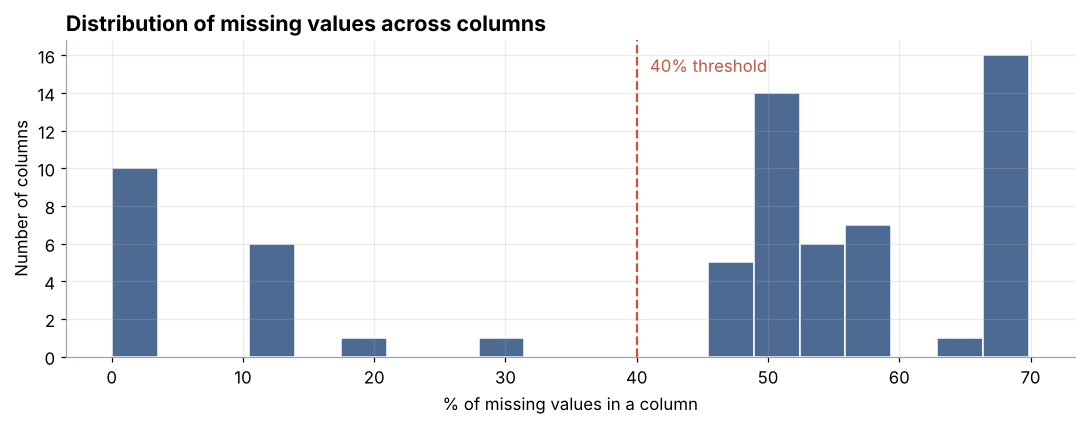

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(missing.pct_missing[missing.pct_missing > 0] * 100, bins=20, color=BASE, edgecolor="white")
ax.axvline(40, color=RISK, ls="--", lw=1.5)
ax.text(41, ax.get_ylim()[1] * 0.9, "40% threshold", color=RISK)
ax.set_title("Distribution of missing values across columns")
ax.set_xlabel("% of missing values in a column")
ax.set_ylabel("Number of columns")
plt.tight_layout()
plt.savefig("images/01_missing_values.png", bbox_inches="tight")
plt.show()

Most columns with many missing values (> 40%) describe **the building the client lives in** (suffixes `_AVG`, `_MODE`, `_MEDI`).
They have little business value and are hard to interpret, so **I drop them**.

Exception: `EXT_SOURCE_1` and `EXT_SOURCE_3` (external credit scores) – despite the gaps they are key risk indicators, so **they are kept**.

In [6]:
KEEP = ["EXT_SOURCE_1", "EXT_SOURCE_3"]
high_missing = missing.index[missing.pct_missing > 0.40]
housing_cols = [c for c in app.columns if c.endswith(("_AVG", "_MODE", "_MEDI"))]
drop_cols = sorted((set(high_missing) | set(housing_cols)) - set(KEEP))

df = app.drop(columns=drop_cols).copy()
print(f"Dropped {len(drop_cols)} columns → {df.shape[1]} columns left")

Dropped 48 columns → 74 columns left


### 3.2 Invalid and unusual values

In [7]:
# DAYS_* columns are stored as a negative number of days before the application date
df[["DAYS_BIRTH", "DAYS_EMPLOYED", "DAYS_REGISTRATION", "DAYS_ID_PUBLISH"]].describe().T

,count,mean,std,min,25%,50%,75%,max
DAYS_BIRTH,"307,511.000","-16,036.995","4,363.989","-25,229.000","-19,682.000","-15,750.000","-12,413.000","-7,489.000"
DAYS_EMPLOYED,"307,511.000","63,815.046","141,275.767","-17,912.000","-2,760.000","-1,213.000",-289.000,"365,243.000"
DAYS_REGISTRATION,"307,511.000","-4,986.120","3,522.886","-24,672.000","-7,479.500","-4,504.000","-2,010.000",0.000
DAYS_ID_PUBLISH,"307,511.000","-2,994.202","1,509.450","-7,197.000","-4,299.000","-3,254.000","-1,720.000",0.000


`DAYS_EMPLOYED` has a maximum of **365,243 days (≈ 1,000 years)** – clearly a placeholder value, not a real employment length. Let's check who it applies to:

In [8]:
anom = df["DAYS_EMPLOYED"] == 365243
print(f"Rows with value 365243: {anom.sum():,} ({anom.mean():.1%})")
print(df.loc[anom, "NAME_INCOME_TYPE"].value_counts())
print(f"\nDefault rate – placeholder group: {df.loc[anom, 'TARGET'].mean():.2%}")
print(f"Default rate – everyone else:     {df.loc[~anom, 'TARGET'].mean():.2%}")

Rows with value 365243: 55,374 (18.0%)
NAME_INCOME_TYPE
Pensioner     55352
Unemployed       22
Name: count, dtype: int64

Default rate – placeholder group: 5.40%
Default rate – everyone else:     8.66%


The value 365243 appears **only for pensioners and unemployed clients** – it is a "not employed" code, not a random error.
This group has a clearly **lower** default rate, so the information is valuable. I replace the value with `NaN` and keep it as a separate flag `NOT_EMPLOYED`.

In [9]:
df["NOT_EMPLOYED"] = anom.astype(int)
df.loc[anom, "DAYS_EMPLOYED"] = np.nan

# Gender 'XNA' – only 4 records, removed
print("CODE_GENDER:", df["CODE_GENDER"].value_counts().to_dict())
df = df[df["CODE_GENDER"] != "XNA"]

# Income – check for extreme values
print(df["AMT_INCOME_TOTAL"].describe(percentiles=[.5, .99, .999]).apply(lambda x: f"{x:,.0f}"))

CODE_GENDER: {'F': 202448, 'M': 105059, 'XNA': 4}
count        307,507
mean         168,798
std          237,125
min           25,650
50%          147,150
99%          472,500
99.9%        900,000
max      117,000,000
Name: AMT_INCOME_TOTAL, dtype: str


The maximum income (117 million) is unrealistic compared with the median (~147 thousand). To stop extreme values from distorting charts and ratios, I **cap income at the 99.9th percentile** (*winsorisation*) – the rows themselves stay in the data.

In [10]:
cap = df["AMT_INCOME_TOTAL"].quantile(0.999)
df["AMT_INCOME_TOTAL"] = df["AMT_INCOME_TOTAL"].clip(upper=cap)

# Fill missing values in key categorical columns
df["OCCUPATION_TYPE"] = df["OCCUPATION_TYPE"].fillna("Unknown")
df["NAME_TYPE_SUITE"] = df["NAME_TYPE_SUITE"].fillna("Unknown")
print(f"After cleaning: {df.shape[0]:,} rows × {df.shape[1]} columns")

After cleaning: 307,507 rows × 75 columns


### 3.3 Feature engineering

I create ratios that are actually used in credit assessment:

| Feature | Formula | Business meaning |
|---|---|---|
| `AGE_YEARS` | −DAYS_BIRTH / 365 | client age |
| `YEARS_EMPLOYED` | −DAYS_EMPLOYED / 365 | length of employment |
| `CREDIT_INCOME_RATIO` | loan amount / annual income | size of the loan relative to income |
| `ANNUITY_INCOME_RATIO` | annuity / annual income | income burden of the repayment (similar to **DTI**) |
| `CREDIT_TERM` | loan amount / annuity | approximate number of instalments (loan length) |
| `CREDIT_GOODS_RATIO` | loan amount / goods price | does the client borrow more than the goods are worth (similar to **LTV**) |
| `EXT_SOURCE_MEAN` | mean of EXT_SOURCE_1–3 | combined external credit score |

In [11]:
df["AGE_YEARS"] = -df["DAYS_BIRTH"] / 365.25
df["YEARS_EMPLOYED"] = -df["DAYS_EMPLOYED"] / 365.25
df["CREDIT_INCOME_RATIO"] = df["AMT_CREDIT"] / df["AMT_INCOME_TOTAL"]
df["ANNUITY_INCOME_RATIO"] = df["AMT_ANNUITY"] / df["AMT_INCOME_TOTAL"]
df["CREDIT_TERM"] = df["AMT_CREDIT"] / df["AMT_ANNUITY"]
df["CREDIT_GOODS_RATIO"] = df["AMT_CREDIT"] / df["AMT_GOODS_PRICE"]
df["EXT_SOURCE_MEAN"] = df[["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]].mean(axis=1)

df[["AGE_YEARS", "YEARS_EMPLOYED", "CREDIT_INCOME_RATIO", "ANNUITY_INCOME_RATIO",
    "CREDIT_TERM", "CREDIT_GOODS_RATIO", "EXT_SOURCE_MEAN"]].describe().T

,count,mean,std,min,25%,50%,75%,max
AGE_YEARS,"307,507.000",43.907,11.948,20.504,33.985,43.121,53.886,69.073
YEARS_EMPLOYED,"252,133.000",6.527,6.402,-0.000,2.100,4.512,8.693,49.040
CREDIT_INCOME_RATIO,"307,507.000",3.958,2.689,0.083,2.019,3.265,5.160,84.737
ANNUITY_INCOME_RATIO,"307,495.000",0.181,0.095,0.007,0.115,0.163,0.229,1.876
CREDIT_TERM,"307,495.000",21.612,7.824,8.037,15.614,20.000,27.100,45.305
CREDIT_GOODS_RATIO,"307,229.000",1.123,0.124,0.150,1.000,1.119,1.198,6.000
EXT_SOURCE_MEAN,"307,335.000",0.509,0.150,0.000,0.414,0.525,0.623,0.879


## 4. Portfolio Overview

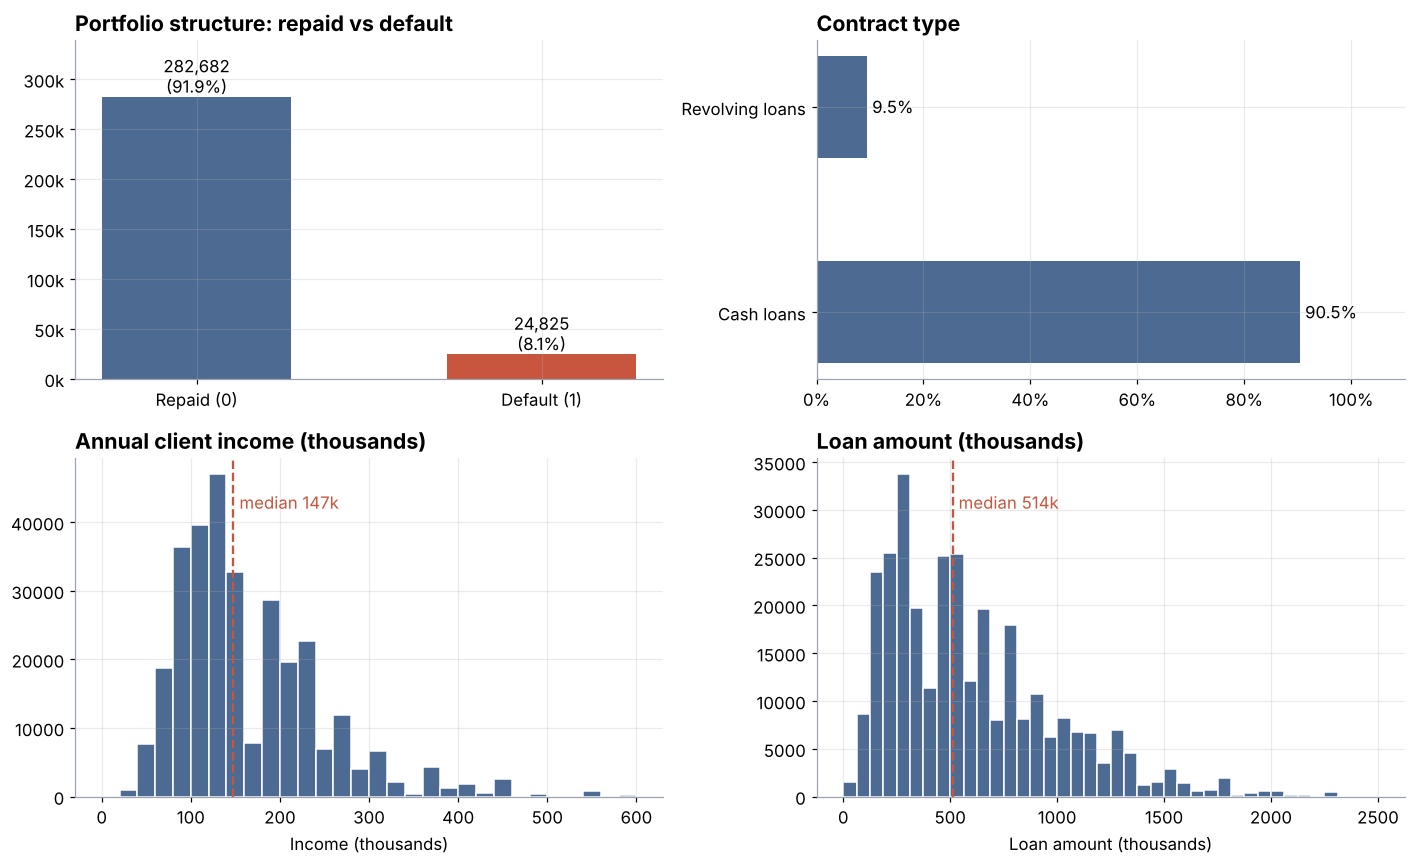

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

# (a) Repaid vs default
ax = axes[0, 0]
counts = df["TARGET"].value_counts().sort_index()
ax.bar(["Repaid (0)", "Default (1)"], counts.values, color=[BASE, RISK], width=0.55)
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}\n({v / counts.sum():.1%})", ha="center", va="bottom")
ax.set_title("Portfolio structure: repaid vs default")
ax.set_ylim(0, counts.max() * 1.2)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))

# (b) Contract type
ax = axes[0, 1]
ct = df["NAME_CONTRACT_TYPE"].value_counts(normalize=True)
ax.barh(ct.index, ct.values, color=BASE, height=0.5)
for i, v in enumerate(ct.values):
    ax.text(v, i, f" {v:.1%}", va="center")
ax.set_title("Contract type")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlim(0, 1.1)

# (c) Income distribution
ax = axes[1, 0]
ax.hist(df["AMT_INCOME_TOTAL"] / 1000, bins=30, range=(0, 600), color=BASE, edgecolor="white")
med = df["AMT_INCOME_TOTAL"].median() / 1000
ax.axvline(med, color=RISK, ls="--")
ax.text(med * 1.05, ax.get_ylim()[1] * 0.85, f"median {med:,.0f}k", color=RISK)
ax.set_title("Annual client income (thousands)")
ax.set_xlabel("Income (thousands)")

# (d) Loan amount
ax = axes[1, 1]
ax.hist(df["AMT_CREDIT"] / 1000, bins=40, range=(0, 2500), color=BASE, edgecolor="white")
med = df["AMT_CREDIT"].median() / 1000
ax.axvline(med, color=RISK, ls="--")
ax.text(med * 1.05, ax.get_ylim()[1] * 0.85, f"median {med:,.0f}k", color=RISK)
ax.set_title("Loan amount (thousands)")
ax.set_xlabel("Loan amount (thousands)")

plt.tight_layout()
plt.savefig("images/02_portfolio_overview.png", bbox_inches="tight")
plt.show()

In [13]:
print(f"Share of women:                    {(df['CODE_GENDER'] == 'F').mean():.1%}")
print(f"Median age:                        {df['AGE_YEARS'].median():.0f} years")
print(f"Median loan / income:              {df['CREDIT_INCOME_RATIO'].median():.1f}x")
print(f"Median annuity / income (DTI):     {df['ANNUITY_INCOME_RATIO'].median():.1%}")
print(f"Median instalments (loan/annuity): {df['CREDIT_TERM'].median():.0f}")

Share of women:                    65.8%
Median age:                        43 years
Median loan / income:              3.3x
Median annuity / income (DTI):     16.3%
Median instalments (loan/annuity): 20


**Observations:**
- **~90%** of the portfolio are cash loans; the rest are revolving loans.
- A typical client earns about **147k** a year and borrows about **3.3× their annual income**.
- The annuity (`AMT_ANNUITY`) is on average about **16%** of the client's annual income.
- Income and loan amount are **right-skewed** – that is why I use the median rather than the mean.

## 5. Risk Drivers – What Drives Default?

For each feature I calculate the **default rate in each group** and compare it with the portfolio average (dashed line).
🟥 red = risk **above** average, 🟦 blue = risk **below** average.

In [14]:
AVG = df["TARGET"].mean()

def plot_default_rate(data, col, title, fname, order=None, min_n=500, figsize=(10, 5)):
    """Bar chart of the default rate per group of a feature, with the portfolio average line."""
    g = (data.groupby(col, observed=True)["TARGET"]
             .agg(default_rate="mean", n="size"))
    g = g[g["n"] >= min_n]
    g = g.reindex([o for o in order if o in g.index]) if order is not None \
        else g.sort_values("default_rate")

    fig, ax = plt.subplots(figsize=figsize)
    labels = [str(i) for i in g.index]
    colors = [RISK if r > AVG else BASE for r in g["default_rate"]]
    ax.barh(labels, g["default_rate"], color=colors, height=0.6)
    for i, (r, n) in enumerate(zip(g["default_rate"], g["n"])):
        ax.text(r + 0.002, i, f"{r:.1%}  (n={n:,})", va="center", fontsize=9, color=DARK,
                bbox=dict(facecolor="white", edgecolor="none", pad=0.6))
    if order is not None:
        ax.invert_yaxis()   # keep the natural top-to-bottom order
    ax.axvline(AVG, color=DARK, ls="--", lw=1, label=f"portfolio average {AVG:.1%}")
    ax.legend(frameon=False, loc="lower right", fontsize=9)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    ax.set_xlim(0, g["default_rate"].max() * 1.35)
    ax.set_xlabel("Default rate")
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    plt.savefig(f"images/{fname}.png", bbox_inches="tight")
    plt.show()
    return g

### 5.1 Client age

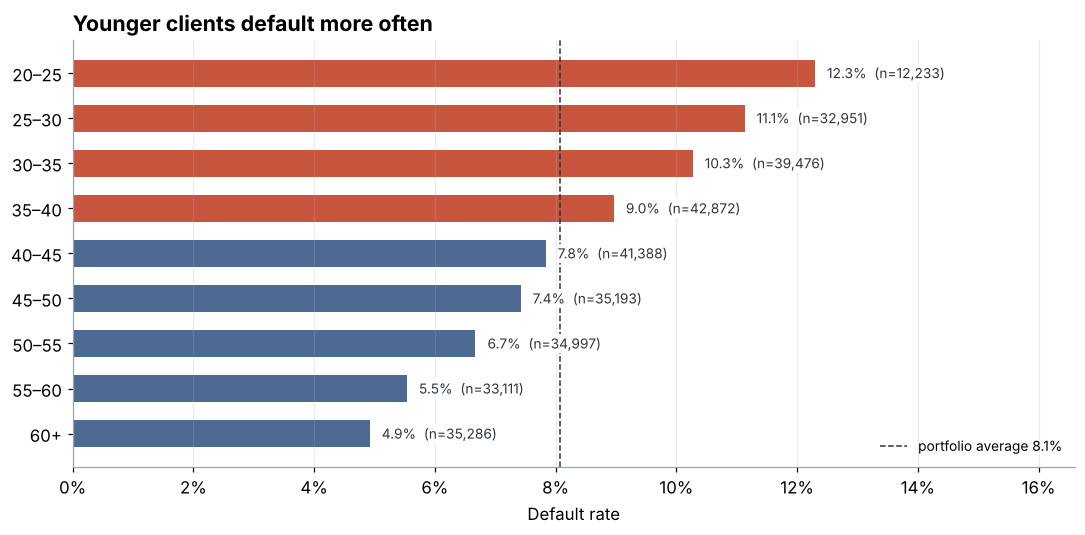

,default_rate,n
AGE_GROUP,,
20–25,0.123,12233
25–30,0.111,32951
30–35,0.103,39476
35–40,0.090,42872
40–45,0.078,41388
45–50,0.074,35193
50–55,0.067,34997
55–60,0.055,33111
60+,0.049,35286


In [15]:
age_bins = [20, 25, 30, 35, 40, 45, 50, 55, 60, 70]
age_labels = ["20–25", "25–30", "30–35", "35–40", "40–45", "45–50", "50–55", "55–60", "60+"]
df["AGE_GROUP"] = pd.cut(df["AGE_YEARS"], bins=age_bins, labels=age_labels)

plot_default_rate(df, "AGE_GROUP", "Younger clients default more often",
                  "03_default_by_age", order=age_labels)

**Insight:** risk **falls steadily with age** – clients aged 20–25 default about **2.5× more often** than clients aged 60+.
Younger clients usually have a shorter credit history and less stable income.

> ⚠️ Age is a sensitive attribute – in the EU it should not be the sole reason to reject a loan. I treat it as a **signal to monitor**, not a decision rule.

### 5.2 Length of employment

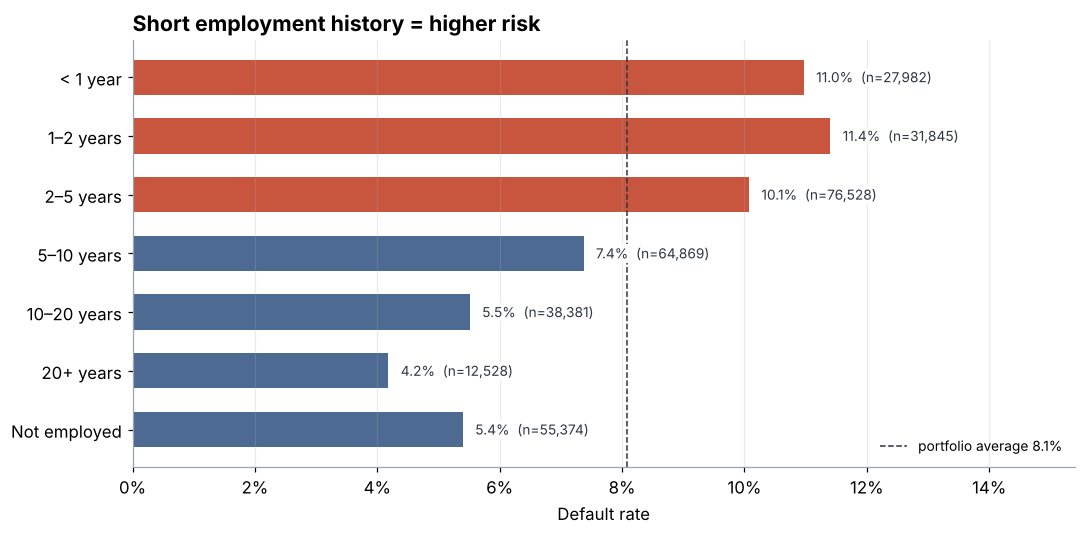

,default_rate,n
EMPLOYED_GROUP,,
< 1 year,0.110,27982
1–2 years,0.114,31845
2–5 years,0.101,76528
5–10 years,0.074,64869
10–20 years,0.055,38381
20+ years,0.042,12528
Not employed,0.054,55374


In [16]:
emp_bins = [-0.01, 1, 2, 5, 10, 20, 50]
emp_labels = ["< 1 year", "1–2 years", "2–5 years", "5–10 years", "10–20 years", "20+ years"]
df["EMPLOYED_GROUP"] = pd.cut(df["YEARS_EMPLOYED"], bins=emp_bins, labels=emp_labels)
df["EMPLOYED_GROUP"] = df["EMPLOYED_GROUP"].cat.add_categories("Not employed")
df.loc[df["NOT_EMPLOYED"] == 1, "EMPLOYED_GROUP"] = "Not employed"

plot_default_rate(df, "EMPLOYED_GROUP", "Short employment history = higher risk",
                  "04_default_by_employment", order=emp_labels + ["Not employed"])

**Insight:** clients employed for **less than 2 years** default about **2× more often** than clients employed for 10+ years.
Job stability is one of the simplest and most reliable risk signals.

### 5.3 Income type, education and occupation

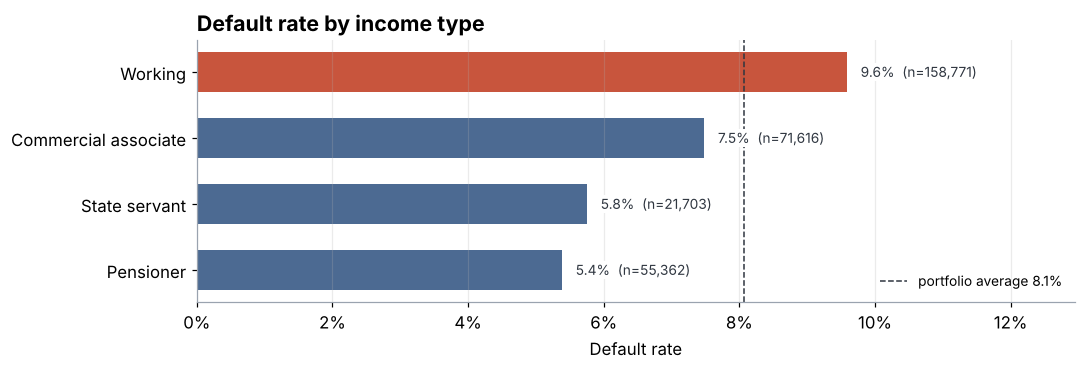

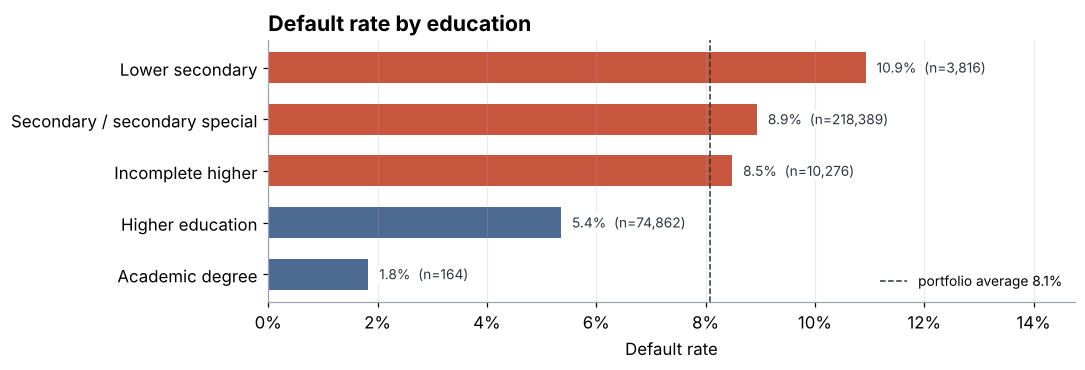

,default_rate,n
NAME_EDUCATION_TYPE,,
Lower secondary,0.109,3816
Secondary / secondary special,0.089,218389
Incomplete higher,0.085,10276
Higher education,0.054,74862
Academic degree,0.018,164


In [17]:
plot_default_rate(df, "NAME_INCOME_TYPE", "Default rate by income type",
                  "05_default_by_income_type", min_n=1000, figsize=(10, 3.5))

plot_default_rate(df, "NAME_EDUCATION_TYPE", "Default rate by education",
                  "06_default_by_education",
                  order=["Lower secondary", "Secondary / secondary special",
                         "Incomplete higher", "Higher education", "Academic degree"],
                  min_n=100, figsize=(10, 3.5))

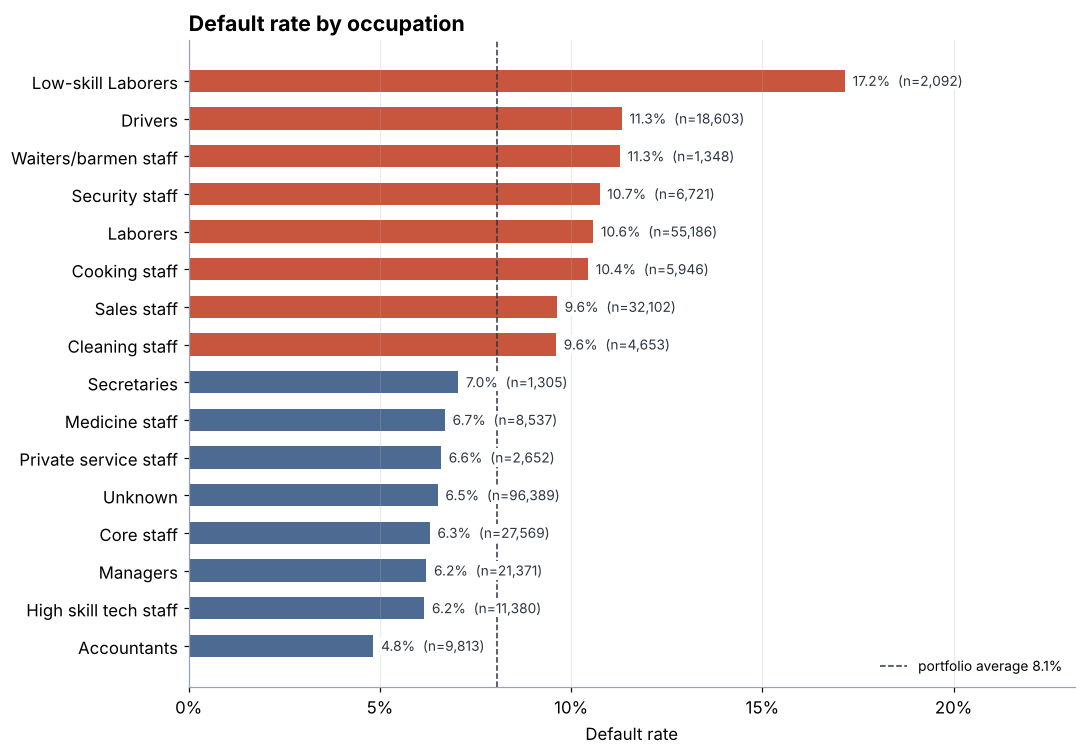

,default_rate,n
OCCUPATION_TYPE,,
Accountants,0.048,9813
High skill tech staff,0.062,11380
Managers,0.062,21371
Core staff,0.063,27569
Unknown,0.065,96389
Private service staff,0.066,2652
Medicine staff,0.067,8537
Secretaries,0.070,1305
Cleaning staff,0.096,4653


In [18]:
plot_default_rate(df, "OCCUPATION_TYPE", "Default rate by occupation",
                  "07_default_by_occupation", min_n=1000, figsize=(10, 7))

**Insights:**
- **Pensioners** and **state servants** are the safest groups (~5.5%) – stable, predictable income.
- **Higher education** is linked to almost **2× lower** risk than lower secondary education.
- The highest risk is among **low-skill laborers** (~17%) and drivers, security staff and waiters – jobs with unstable or low income.
  The lowest is among accountants, managers and high-skill tech staff.

### 5.4 Repayment burden and loan size

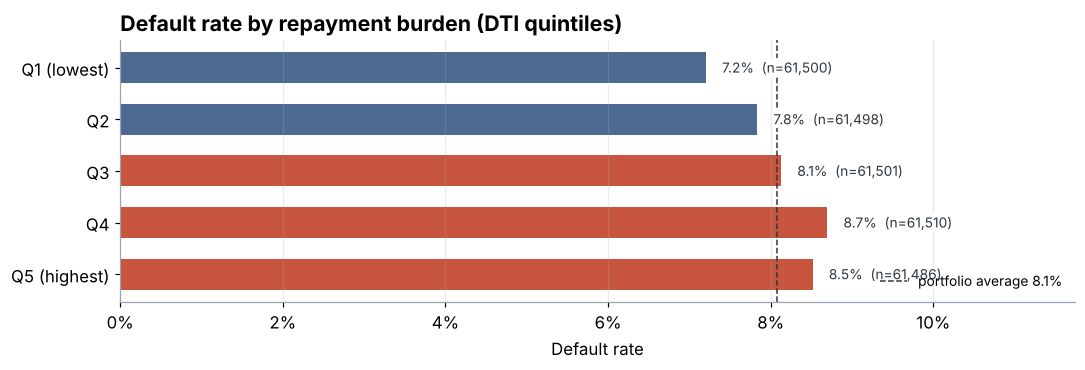

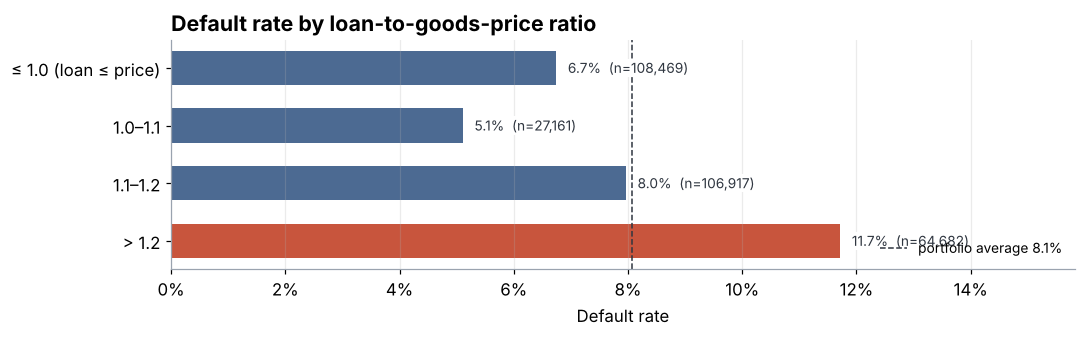

,default_rate,n
LTV_GROUP,,
≤ 1.0 (loan ≤ price),0.067,108469
1.0–1.1,0.051,27161
1.1–1.2,0.080,106917
> 1.2,0.117,64682


In [19]:
dti_order = ["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"]
df["DTI_GROUP"] = pd.qcut(df["ANNUITY_INCOME_RATIO"], q=5, labels=dti_order)
dti_tab = plot_default_rate(df, "DTI_GROUP", "Default rate by repayment burden (DTI quintiles)",
                            "08_default_by_dti", order=dti_order, figsize=(10, 3.5))

ltv_order = ["≤ 1.0 (loan ≤ price)", "1.0–1.1", "1.1–1.2", "> 1.2"]
df["LTV_GROUP"] = pd.cut(df["CREDIT_GOODS_RATIO"], bins=[0, 1.0, 1.1, 1.2, 10], labels=ltv_order)
plot_default_rate(df, "LTV_GROUP", "Default rate by loan-to-goods-price ratio",
                  "09_default_by_ltv", order=ltv_order, figsize=(10, 3.2))

**Insights:**
- The repayment burden (DTI) separates risk **less than expected** – the relationship is weak. The lender probably already limits very high DTI at the approval stage.
- The **loan-to-goods-price ratio** is more interesting: clients who borrow **more than the value of the goods** (e.g. with added insurance or extra cash) default more often.

### 5.5 Region and external credit score

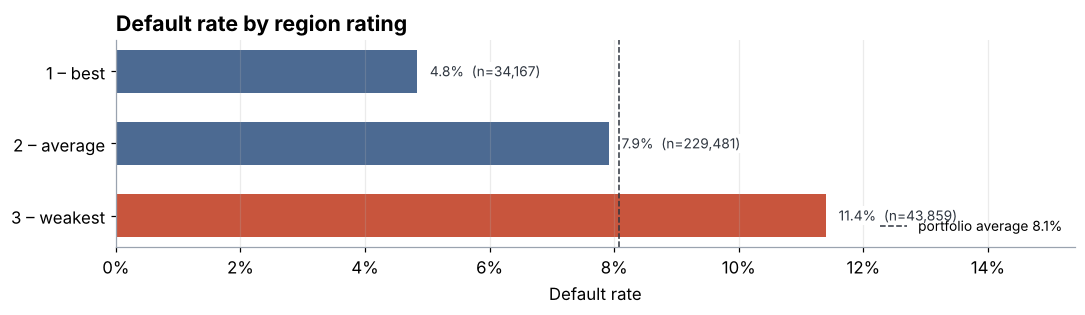

,default_rate,n
REGION_RATING,,
1 – best,0.048,34167
2 – average,0.079,229481
3 – weakest,0.114,43859


In [20]:
region_order = ["1 – best", "2 – average", "3 – weakest"]
df["REGION_RATING"] = df["REGION_RATING_CLIENT_W_CITY"].map(dict(zip([1, 2, 3], region_order)))
plot_default_rate(df, "REGION_RATING", "Default rate by region rating",
                  "10_default_by_region", order=region_order, figsize=(10, 3))

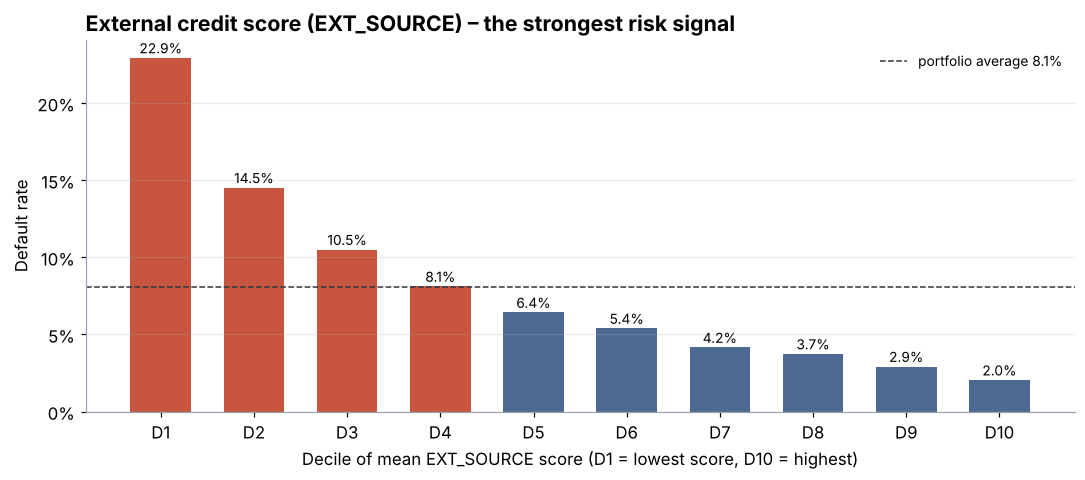

D1: 22.9%  vs  D10: 2.0%  →  11x difference


In [21]:
df["EXT_DECILE"] = pd.qcut(df["EXT_SOURCE_MEAN"], q=10, labels=[f"D{i}" for i in range(1, 11)])
ext = df.groupby("EXT_DECILE", observed=True)["TARGET"].mean()

fig, ax = plt.subplots(figsize=(10, 4.5))
colors = [RISK if r > AVG else BASE for r in ext.values]
ax.bar(ext.index.astype(str), ext.values, color=colors, width=0.65)
for i, r in enumerate(ext.values):
    ax.text(i, r + 0.003, f"{r:.1%}", ha="center", fontsize=9)
ax.axhline(AVG, color=DARK, ls="--", lw=1, label=f"portfolio average {AVG:.1%}")
ax.legend(frameon=False, loc="upper right", fontsize=9)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_title("External credit score (EXT_SOURCE) – the strongest risk signal")
ax.set_xlabel("Decile of mean EXT_SOURCE score (D1 = lowest score, D10 = highest)")
ax.set_ylabel("Default rate")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.savefig("images/11_default_by_ext_source.png", bbox_inches="tight")
plt.show()

print(f"D1: {ext.iloc[0]:.1%}  vs  D10: {ext.iloc[-1]:.1%}  →  {ext.iloc[0] / ext.iloc[-1]:.0f}x difference")

**Insight:** external credit scores (`EXT_SOURCE`) are **by far the strongest driver** in the dataset.
Clients in the lowest decile default many times more often than clients in the highest. Any approval rule should be built primarily on this score.

### 5.6 Summary: correlation of numeric features with default

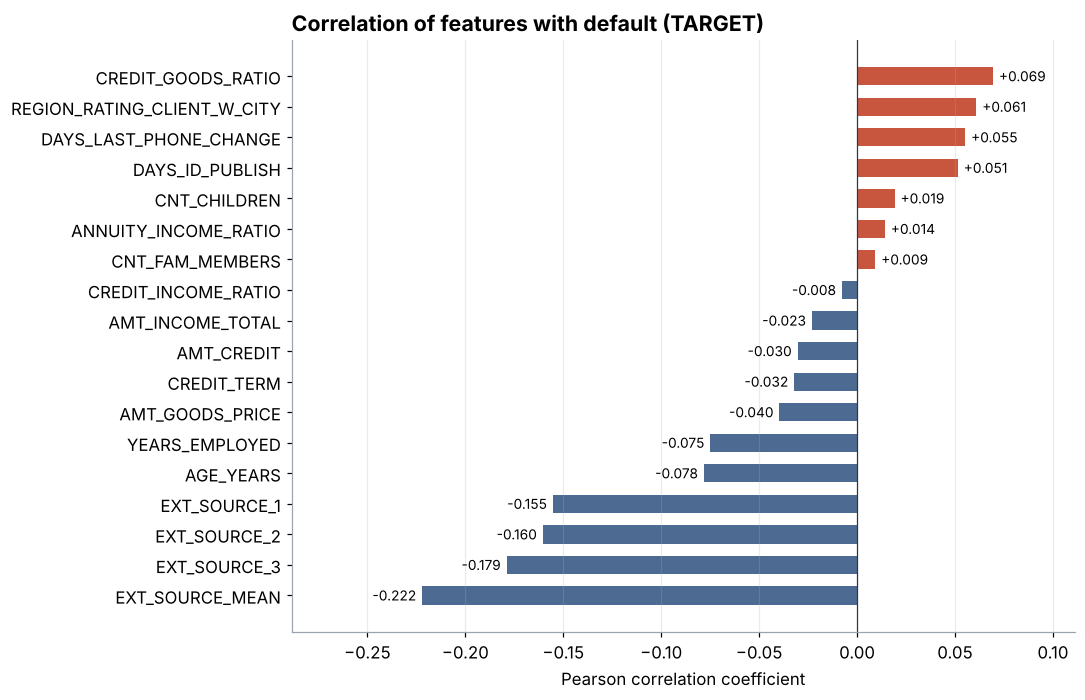

In [22]:
num_cols = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "EXT_SOURCE_MEAN",
            "AGE_YEARS", "YEARS_EMPLOYED", "REGION_RATING_CLIENT_W_CITY",
            "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_GOODS_PRICE",
            "CREDIT_INCOME_RATIO", "ANNUITY_INCOME_RATIO", "CREDIT_TERM",
            "CREDIT_GOODS_RATIO", "DAYS_ID_PUBLISH", "DAYS_LAST_PHONE_CHANGE",
            "CNT_CHILDREN", "CNT_FAM_MEMBERS"]
corr = df[num_cols + ["TARGET"]].corr()["TARGET"].drop("TARGET").sort_values()

fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(corr.index, corr.values, color=[BASE if v < 0 else RISK for v in corr.values], height=0.6)
ax.axvline(0, color=DARK, lw=0.8)
for i, v in enumerate(corr.values):
    ax.text(v + (0.003 if v >= 0 else -0.003), i, f"{v:+.3f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=9)
ax.set_title("Correlation of features with default (TARGET)")
ax.set_xlabel("Pearson correlation coefficient")
ax.set_xlim(corr.min() * 1.3, corr.max() * 1.6)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig("images/12_correlation_with_target.png", bbox_inches="tight")
plt.show()

Negative correlation = the higher the value, the **lower** the risk (e.g. EXT_SOURCE, age, employment length). Positive = the higher the value, the **higher** the risk (e.g. a weaker region rating).
The correlations are numerically small, which is typical for credit data with a rare event (8%). The differences in default rate between groups shown above are more informative.

## 6. Credit Bureau History

The `bureau` table contains the client's **previous loans at other institutions** (1 row = 1 loan).
I aggregate it to client level to check whether past behaviour predicts future default.

In [23]:
bureau["IS_ACTIVE"] = (bureau["CREDIT_ACTIVE"] == "Active").astype(int)
bureau["HAD_OVERDUE"] = (bureau["AMT_CREDIT_MAX_OVERDUE"].fillna(0) > 0).astype(int)
bureau["IS_BAD"] = bureau["CREDIT_ACTIVE"].isin(["Bad debt", "Sold"]).astype(int)

bureau_agg = bureau.groupby("SK_ID_CURR").agg(
    BUREAU_CREDITS=("SK_ID_BUREAU", "count"),
    BUREAU_ACTIVE=("IS_ACTIVE", "sum"),
    BUREAU_OVERDUE_CNT=("HAD_OVERDUE", "sum"),
    BUREAU_BAD_CNT=("IS_BAD", "sum"),
    BUREAU_DEBT=("AMT_CREDIT_SUM_DEBT", "sum"),
    BUREAU_DAYS_LAST_CREDIT=("DAYS_CREDIT", "max"),
).reset_index()

df = df.merge(bureau_agg, on="SK_ID_CURR", how="left")
df["HAS_BUREAU"] = df["BUREAU_CREDITS"].notna().astype(int)
df["BUREAU_DEBT_INCOME"] = df["BUREAU_DEBT"] / df["AMT_INCOME_TOTAL"]

print(f"Clients with bureau history: {df['HAS_BUREAU'].mean():.1%}")
bureau_agg.describe().T

Clients with bureau history: 85.7%


,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,"305,811.000","278,047.300","102,849.568","100,001.000","188,878.500","277,895.000","367,184.500","456,255.000"
BUREAU_CREDITS,"305,811.000",5.613,4.430,1.000,2.000,4.000,8.000,116.000
BUREAU_ACTIVE,"305,811.000",2.062,1.792,0.000,1.000,2.000,3.000,32.000
BUREAU_OVERDUE_CNT,"305,811.000",0.397,0.814,0.000,0.000,0.000,1.000,12.000
BUREAU_BAD_CNT,"305,811.000",0.021,0.159,0.000,0.000,0.000,0.000,9.000
BUREAU_DEBT,"305,811.000","653,914.190","1,640,690.814","-6,981,558.210",0.000,"173,367.000","676,541.250","334,498,331.205"
BUREAU_DAYS_LAST_CREDIT,"305,811.000",-490.943,533.529,"-2,922.000",-623.000,-305.000,-149.000,0.000


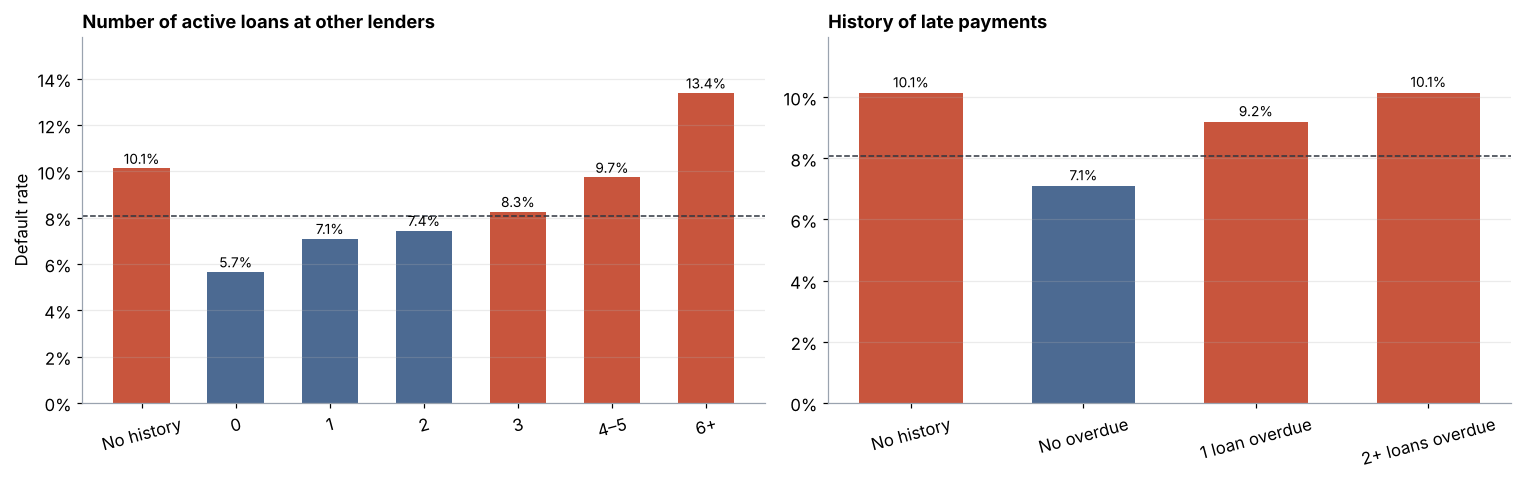

In [24]:
active_order = ["No history", "0", "1", "2", "3", "4–5", "6+"]
df["ACTIVE_GROUP"] = pd.cut(df["BUREAU_ACTIVE"], bins=[-1, 0, 1, 2, 3, 5, 100],
                            labels=active_order[1:])
df["ACTIVE_GROUP"] = df["ACTIVE_GROUP"].cat.add_categories("No history")
df.loc[df["HAS_BUREAU"] == 0, "ACTIVE_GROUP"] = "No history"

overdue_order = ["No history", "No overdue", "1 loan overdue", "2+ loans overdue"]
df["OVERDUE_GROUP"] = np.select(
    [df["HAS_BUREAU"] == 0, df["BUREAU_OVERDUE_CNT"] == 0, df["BUREAU_OVERDUE_CNT"] == 1],
    overdue_order[:3], default=overdue_order[3])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, col, order, title in [
    (axes[0], "ACTIVE_GROUP", active_order, "Number of active loans at other lenders"),
    (axes[1], "OVERDUE_GROUP", overdue_order, "History of late payments"),
]:
    g = df.groupby(col, observed=True)["TARGET"].agg(["mean", "size"]).reindex(order)
    ax.bar(g.index.astype(str), g["mean"], color=[RISK if r > AVG else BASE for r in g["mean"]], width=0.6)
    for i, r in enumerate(g["mean"]):
        ax.text(i, r + 0.002, f"{r:.1%}", ha="center", fontsize=9)
    ax.axhline(AVG, color=DARK, ls="--", lw=1)
    ax.set_ylim(0, g["mean"].max() * 1.18)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    ax.set_title(title, fontsize=12)
    ax.tick_params(axis="x", labelrotation=15)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Default rate")
plt.tight_layout()
plt.savefig("images/13_bureau_history.png", bbox_inches="tight")
plt.show()

**Insights:**
- The **number of active loans** at other lenders clearly raises risk – a client with many open obligations is more stretched.
- **Past late payments** increase risk (~10% with 2+ late loans vs ~7% with no late payments) – past behaviour partly predicts future behaviour.
- Clients with **no bureau history** (*thin file*) have **above-average** risk (~10%). The lender knows less about them, so for this group it is worth relying more on other signals (employment length, EXT_SOURCE).

## 7. Risk Segmentation – Scoring Model

Individual features show the direction of risk, but a lending decision needs **one score that combines many signals**.
I build a simple, **interpretable** logistic regression model (an industry standard in banking – easy to explain to regulators) and split clients into risk segments.

> I deliberately **do not use** gender or age in the model – these are protected attributes, and the model should support fair lending decisions.

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score

features_num = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "YEARS_EMPLOYED", "NOT_EMPLOYED",
                "CREDIT_INCOME_RATIO", "ANNUITY_INCOME_RATIO", "CREDIT_TERM",
                "CREDIT_GOODS_RATIO", "REGION_RATING_CLIENT_W_CITY", "DAYS_ID_PUBLISH",
                "DAYS_LAST_PHONE_CHANGE", "BUREAU_ACTIVE", "BUREAU_OVERDUE_CNT",
                "BUREAU_DEBT_INCOME", "HAS_BUREAU"]
features_cat = ["NAME_EDUCATION_TYPE", "NAME_INCOME_TYPE", "NAME_CONTRACT_TYPE", "OCCUPATION_TYPE"]

X = df[features_num].copy()
# Missing-value flags for external scores – a missing score is itself informative
for c in ["EXT_SOURCE_1", "EXT_SOURCE_3"]:
    X[c + "_MISSING"] = X[c].isna().astype(int)
X["BUREAU_DEBT_INCOME"] = X["BUREAU_DEBT_INCOME"].clip(upper=X["BUREAU_DEBT_INCOME"].quantile(0.99))
X = pd.concat([X, pd.get_dummies(df[features_cat], drop_first=True, dtype=int)], axis=1)
y = df["TARGET"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

model = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                      LogisticRegression(max_iter=2000, class_weight="balanced"))
model.fit(X_train, y_train)

p_test = model.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, p_test)
print(f"Number of model features: {X.shape[1]}")
print(f"ROC AUC (test set): {auc:.3f}  →  Gini = {2 * auc - 1:.3f}")

Number of model features: 48
ROC AUC (test set): 0.744  →  Gini = 0.488


**ROC AUC ≈ 0.74** (Gini ≈ 0.49) – a typical result for a simple scorecard-style model in banking (a random model = 0.5).
The goal here is **not to maximise accuracy**, but to rank clients by risk.

### 7.1 Risk segments
I split the test-set clients by predicted risk:
- **High risk** – the riskiest 10% of applications,
- **Medium risk** – the next 30%,
- **Low risk** – the remaining 60%.

In [26]:
scored = pd.DataFrame({"TARGET": y_test.values, "SCORE": p_test})
q60, q90 = np.quantile(scored["SCORE"], [0.60, 0.90])
scored["SEGMENT"] = pd.cut(scored["SCORE"], bins=[-np.inf, q60, q90, np.inf],
                           labels=["Low", "Medium", "High"])

seg = scored.groupby("SEGMENT", observed=True).agg(
    applications=("TARGET", "size"),
    defaults=("TARGET", "sum"),
    default_rate=("TARGET", "mean"),
)
seg["share_of_applications"] = seg["applications"] / seg["applications"].sum()
seg["share_of_defaults"] = seg["defaults"] / seg["defaults"].sum()
seg.style.format({"applications": "{:,}", "defaults": "{:,}", "default_rate": "{:.1%}",
                  "share_of_applications": "{:.0%}", "share_of_defaults": "{:.0%}"})

,applications,defaults,default_rate,share_of_applications,share_of_defaults
SEGMENT,,,,,
Low,"55,352","2,029",3.7%,60%,27%
Medium,"27,675","3,025",10.9%,30%,41%
High,"9,226","2,394",25.9%,10%,32%


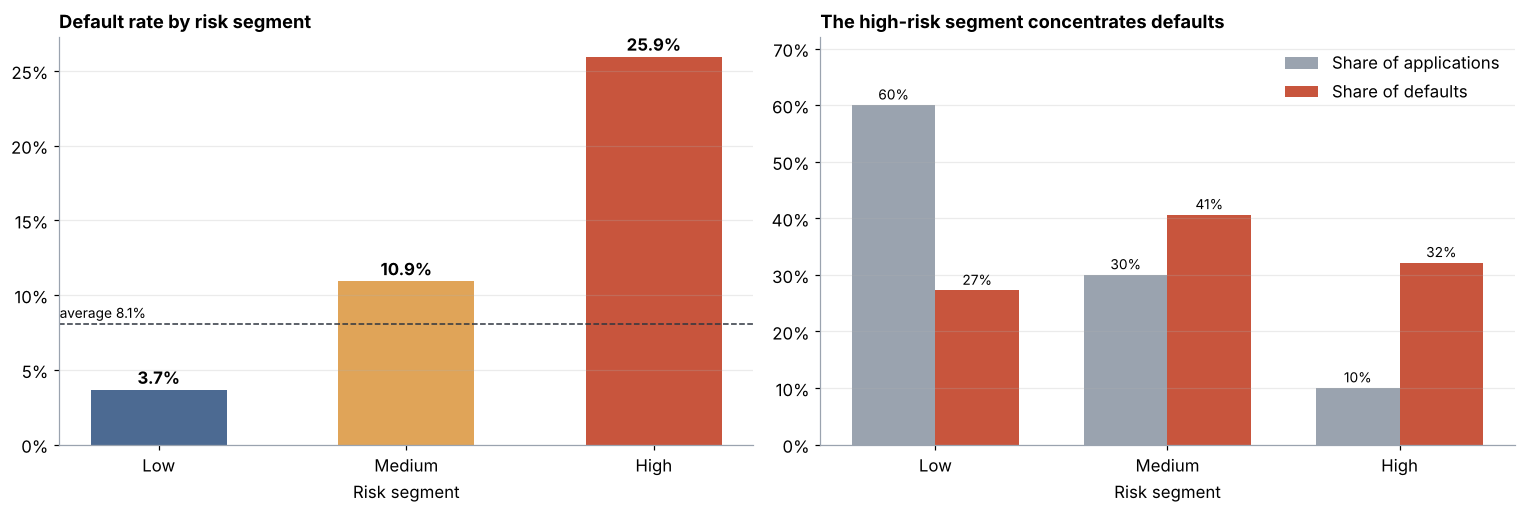

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
seg_colors = [BASE, "#E0A458", RISK]

# (a) default rate per segment
ax = axes[0]
ax.bar(seg.index.astype(str), seg["default_rate"], color=seg_colors, width=0.55)
for i, r in enumerate(seg["default_rate"]):
    ax.text(i, r + 0.004, f"{r:.1%}", ha="center", fontweight="bold")
ax.axhline(AVG, color=DARK, ls="--", lw=1)
ax.text(-0.4, AVG + 0.004, f"average {AVG:.1%}", fontsize=9)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_title("Default rate by risk segment", fontsize=12)
ax.set_xlabel("Risk segment")
ax.grid(axis="x", visible=False)

# (b) share of applications vs share of defaults
ax = axes[1]
x = np.arange(len(seg))
ax.bar(x - 0.18, seg["share_of_applications"], width=0.36, color=GREY, label="Share of applications")
ax.bar(x + 0.18, seg["share_of_defaults"], width=0.36, color=RISK, label="Share of defaults")
for i in range(len(seg)):
    ax.text(i - 0.18, seg["share_of_applications"].iloc[i] + 0.01, f"{seg['share_of_applications'].iloc[i]:.0%}", ha="center", fontsize=9)
    ax.text(i + 0.18, seg["share_of_defaults"].iloc[i] + 0.01, f"{seg['share_of_defaults'].iloc[i]:.0%}", ha="center", fontsize=9)
ax.set_xticks(x, seg.index.astype(str))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_title("The high-risk segment concentrates defaults", fontsize=12)
ax.set_xlabel("Risk segment")
ax.set_ylim(0, 0.72)
ax.legend(frameon=False, loc="upper right")
ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.savefig("images/14_risk_segments.png", bbox_inches="tight")
plt.show()

### 7.2 Cumulative gains curve

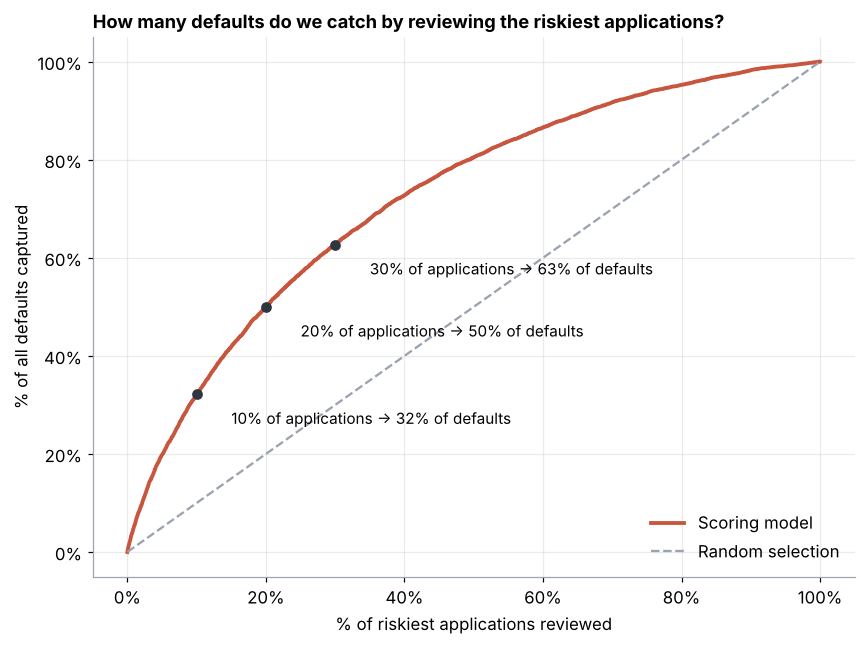

Top 10% riskiest applications contain 32.1% of all defaults
Top 20% riskiest applications contain 50.0% of all defaults
Top 30% riskiest applications contain 62.6% of all defaults


In [28]:
s = scored.sort_values("SCORE", ascending=False).reset_index(drop=True)
pct_apps = np.arange(1, len(s) + 1) / len(s)
pct_def = s["TARGET"].cumsum() / s["TARGET"].sum()

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(pct_apps, pct_def, color=RISK, lw=2.5, label="Scoring model")
ax.plot([0, 1], [0, 1], color=GREY, ls="--", label="Random selection")
for cut in [0.10, 0.20, 0.30]:
    v = pct_def[int(cut * len(s)) - 1]
    ax.scatter(cut, v, color=DARK, zorder=3)
    ax.annotate(f"{cut:.0%} of applications → {v:.0%} of defaults", (cut, v),
                xytext=(cut + 0.05, v - 0.06), fontsize=10)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlabel("% of riskiest applications reviewed")
ax.set_ylabel("% of all defaults captured")
ax.set_title("How many defaults do we catch by reviewing the riskiest applications?", fontsize=12)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig("images/15_gains_curve.png", bbox_inches="tight")
plt.show()

for cut in [0.10, 0.20, 0.30]:
    print(f"Top {cut:.0%} riskiest applications contain {pct_def[int(cut * len(s)) - 1]:.1%} of all defaults")

### 7.3 Which features influence the model most?

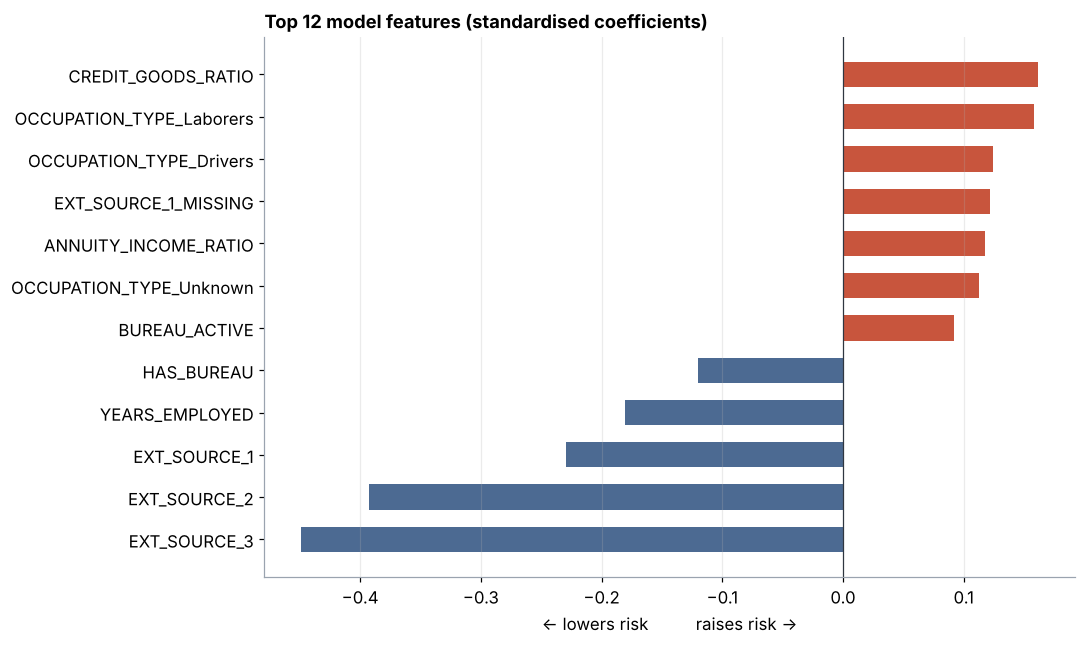

In [29]:
coefs = pd.Series(model[-1].coef_[0], index=X.columns)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(12).sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top.index, top.values, color=[BASE if v < 0 else RISK for v in top.values], height=0.6)
ax.axvline(0, color=DARK, lw=0.8)
ax.set_title("Top 12 model features (standardised coefficients)", fontsize=12)
ax.set_xlabel("← lowers risk          raises risk →")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig("images/16_model_coefficients.png", bbox_inches="tight")
plt.show()

## 8. Conclusions & Recommendations

In [30]:
# Key numbers for the summary
young = df.loc[df["AGE_GROUP"] == "20–25", "TARGET"].mean()
old = df.loc[df["AGE_GROUP"] == "60+", "TARGET"].mean()
short_emp = df.loc[df["EMPLOYED_GROUP"].isin(["< 1 year", "1–2 years"]), "TARGET"].mean()
long_emp = df.loc[df["EMPLOYED_GROUP"].isin(["10–20 years", "20+ years"]), "TARGET"].mean()
od2 = df.loc[df["OVERDUE_GROUP"] == "2+ loans overdue", "TARGET"].mean()
od0 = df.loc[df["OVERDUE_GROUP"] == "No overdue", "TARGET"].mean()

print(f"Average default rate:                     {AVG:.1%}")
print(f"EXT_SOURCE  D1 vs D10:                    {ext.iloc[0]:.1%} vs {ext.iloc[-1]:.1%}")
print(f"Age 20–25 vs 60+:                         {young:.1%} vs {old:.1%}")
print(f"Employment < 2 years vs 10+ years:        {short_emp:.1%} vs {long_emp:.1%}")
print(f"Bureau: 2+ late loans vs no late loans:   {od2:.1%} vs {od0:.1%}")
print(f"High-risk segment – default rate:         {seg.loc['High', 'default_rate']:.1%}")
print(f"High-risk segment – share of defaults:    {seg.loc['High', 'share_of_defaults']:.0%}")
print(f"Low-risk segment – default rate:          {seg.loc['Low', 'default_rate']:.1%}")

Average default rate:                     8.1%
EXT_SOURCE  D1 vs D10:                    22.9% vs 2.0%
Age 20–25 vs 60+:                         12.3% vs 4.9%
Employment < 2 years vs 10+ years:        11.2% vs 5.2%
Bureau: 2+ late loans vs no late loans:   10.1% vs 7.1%
High-risk segment – default rate:         25.9%
High-risk segment – share of defaults:    32%
Low-risk segment – default rate:          3.7%


### Key findings

1. **Portfolio risk level:** 8.1% of clients default, but risk is **very unevenly distributed** across client groups.
2. **The external credit score (EXT_SOURCE) is the strongest signal:** the default rate falls from **22.9%** in the lowest decile to **2.0%** in the highest (**11×** difference).
3. **Client stability matters:** employment under 2 years means **11.2%** defaults vs **5.2%** for 10+ years. Higher education and stable income (pensioners, state servants) also lower risk.
4. **Credit history at other lenders completes the picture:** 6+ active loans means about **13%** defaults, and no history at all (*thin file*) about **10%**.
5. **The scoring model ranks clients well (AUC 0.74):** the **high-risk segment (10% of applications)** has a default rate of **25.9%** and contains **32%** of all defaults, while the low-risk segment (60% of applications) has only **3.7%**.

### Recommendations for the Credit Risk team

1. **Introduce a 3-tier decision path based on the score:**
   - *Low risk* → fast, automated approval (shorter processing time, better client experience),
   - *Medium risk* → standard verification,
   - *High risk* → manual review by an analyst, a lower loan amount or a collateral requirement.
   Manually reviewing just **20%** of the riskiest applications covers **50%** of all defaults.
2. **Control the loan amount relative to the goods price:** applications where the loan exceeds the goods price by more than 20% default about **11.7%** of the time (vs 6.7% when loan ≤ price). Consider limiting extra amounts added to the loan for medium- and high-risk clients.
3. **A separate policy for clients with no credit history (thin file):** instead of automatic rejection – a smaller first loan and gradual limit increases after on-time repayments. This builds the client's history while keeping risk under control.
4. **Monitor the portfolio on a dashboard:** default rate by risk segment, occupation, region and employment length – with an alert when a segment exceeds an agreed threshold.

### Limitations
- The data covers a single period and **has no loan issue dates** – vintage analysis and trends over time are not possible.
- Only **approved** applications are analysed – we don't know how rejected clients would have repaid (*reject inference*).
- The model is intentionally simple and interpretable; more complex models (e.g. gradient boosting) could improve AUC at the cost of transparency.

### Next steps
- Add the `previous_application` and `installments_payments` tables (repayment history at Home Credit).
- Build an interactive **Power BI** dashboard to monitor risk segments.